<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/Projects/Analyzing_Student_Academic_Trends.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Title : Analyzing Student Academic Trends**
Understanding Learning Achievements

In [ ]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("saadaliyaseen/analyzing-student-academic-trends")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'analyzing-student-academic-trends' dataset.
Path to dataset files: /kaggle/input/analyzing-student-academic-trends


## **Load the dataset**

In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("/kaggle/input/analyzing-student-academic-trends/student_exam_scores.csv")

## **Analyze the dataset**

In [ ]:
df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB


In [ ]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


In [ ]:
df.isnull().sum()

,0
student_id,0
hours_studied,0
sleep_hours,0
attendance_percent,0
previous_scores,0
exam_score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
student_id,object
hours_studied,float64
sleep_hours,float64
attendance_percent,float64
previous_scores,int64
exam_score,float64


### **Summary of tasks done so far**

1. Downloaded the "analyzing-student-academic-trends" dataset from Kaggle using kagglehub.
2. Loaded the student_exam_scores.csv file from the downloaded dataset into a pandas DataFrame named df.
3. Displayed the head of the DataFrame to see the first few rows.
4. Used df.info() to get information about the DataFrame, including the data types and non-null counts of each column.
5. Used df.describe() to get descriptive statistics of the numerical columns in the DataFrame.
6. Checked for missing values in each column using df.isnull().sum().
7. Checked for duplicate rows using df.duplicated().sum().
8. Checked the data types of each column using df.dtypes.

## **Visualization of data**

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
print(numerical_cols)

['hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores', 'exam_score']


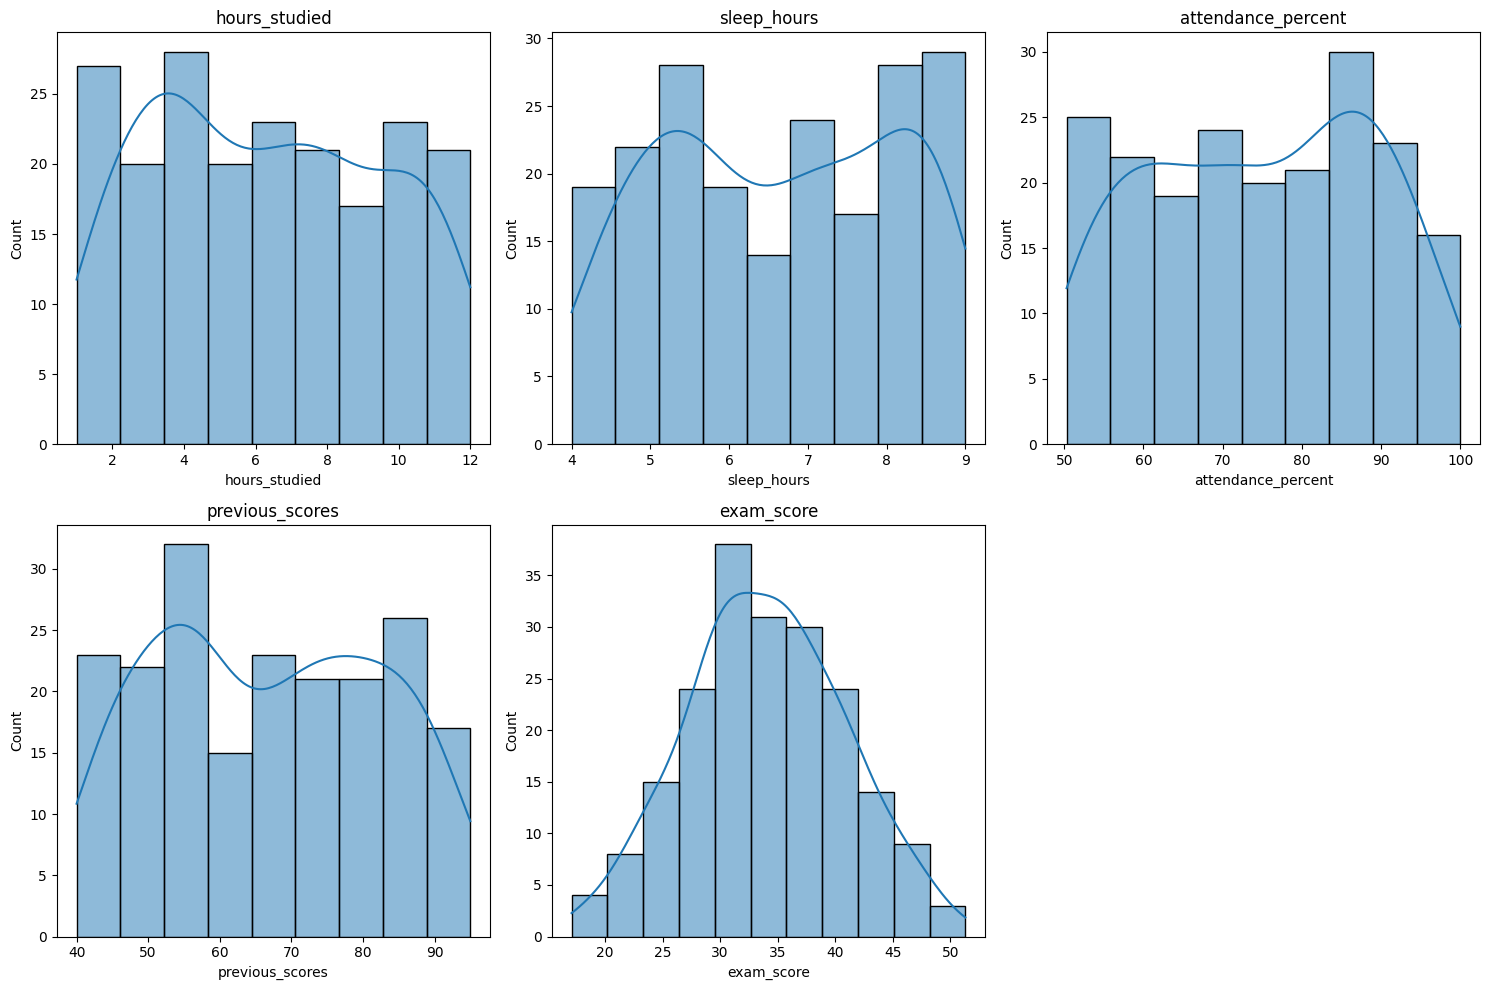

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
num_features = len(numerical_cols)
num_cols = 3
num_rows = math.ceil(num_features / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 5))

# Flatten axes array for easy iteration
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(col)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

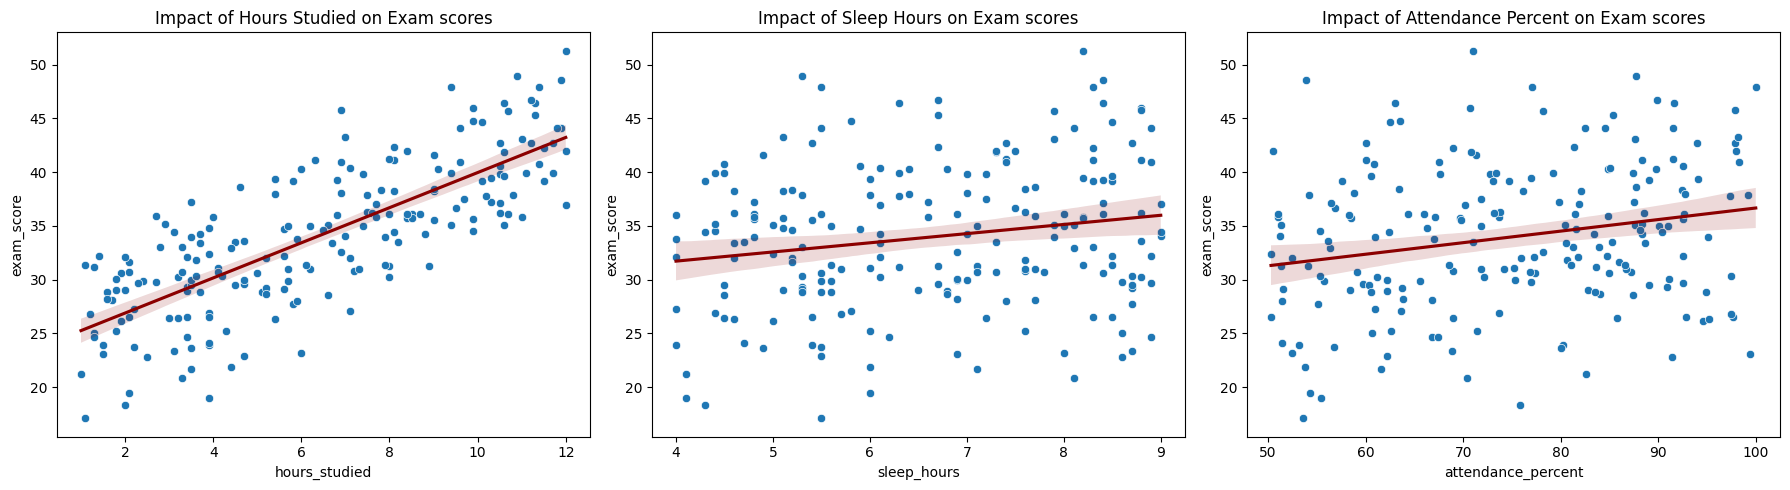

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='hours_studied', y='exam_score', ax=axes[0])
sns.regplot(x="hours_studied", y="exam_score", data=df, scatter=False, color="darkred", ax=axes[0])
axes[0].set_title('Impact of Hours Studied on Exam scores')

sns.scatterplot(data=df, x='sleep_hours', y='exam_score', ax=axes[1])
sns.regplot(x="sleep_hours", y="exam_score", data=df, scatter=False, color="darkred", ax=axes[1])
axes[1].set_title('Impact of Sleep Hours on Exam scores')

sns.scatterplot(data=df, x='attendance_percent', y='exam_score', ax=axes[2])
sns.regplot(x="attendance_percent", y="exam_score", data=df, scatter=False, color="darkred", ax=axes[2])
axes[2].set_title('Impact of Attendance Percent on Exam scores')

plt.tight_layout()
plt.show()

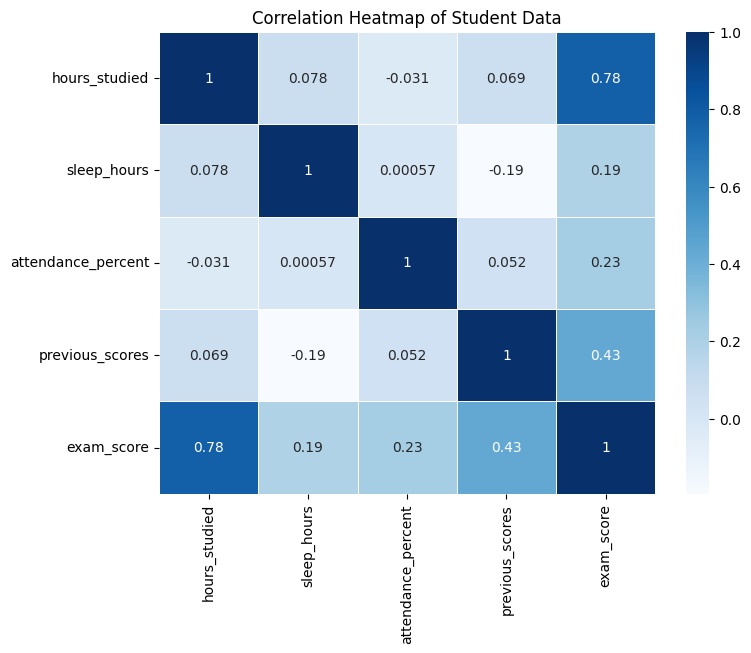

In [ ]:
plt.figure(figsize=(8,6))
corr = df[['hours_studied','sleep_hours','attendance_percent','previous_scores','exam_score']].corr()
sns.heatmap(corr, annot=True, cmap="Blues", linewidths=0.5)
plt.title("Correlation Heatmap of Student Data")
plt.show()

## Report on Visualizations

Here's a summary of the insights from the visualization plots:

### Distribution of Numerical Features (Histograms)

The histograms show the distribution of each numerical feature:
- **Hours Studied**: The distribution appears somewhat skewed towards fewer hours studied, but there is a range of study times.
- **Sleep Hours**: The distribution of sleep hours seems relatively normal, centered around a certain number of hours.
- **Attendance Percent**: The attendance percentage shows a distribution with a spread across the range, indicating varying levels of attendance among students.
- **Previous Scores**: The distribution of previous scores appears somewhat uniform or slightly skewed, covering a wide range of past performance.
- **Exam Score**: The distribution of exam scores seems to be somewhat normally distributed, with a peak around the average score.

### Relationship between Variables and Exam Scores (Scatter Plots with Regression Lines)

The scatter plots with regression lines illustrate the relationships between study habits, attendance, and exam performance:
- **Hours Studied vs. Exam Score**: There is a clear positive linear relationship between hours studied and exam scores. The regression line indicates that as the number of hours studied increases, the exam score tends to increase as well.
- **Sleep Hours vs. Exam Score**: The scatter plot and regression line suggest a weak positive relationship between sleep hours and exam scores. While there might be a slight trend, sleep hours do not appear to be as strong a predictor of exam scores as hours studied or attendance.
- **Attendance Percent vs. Exam Score**: There is a positive linear relationship between attendance percentage and exam scores. Higher attendance generally corresponds to higher exam scores.

### Correlation Heatmap

The correlation heatmap provides a quantitative view of the linear relationships between the numerical features:
- It confirms the positive correlations observed in the scatter plots, with 'hours_studied' and 'attendance_percent' showing stronger positive correlations with 'exam_score' compared to 'sleep_hours'.
- The heatmap also shows the correlations among the independent variables, which can be useful for understanding potential multicollinearity if building a predictive model.

These visualizations provide valuable insights into the factors that may influence student exam performance and can guide further analysis.

## **Predictive Modeling**

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(['student_id', 'exam_score'], axis=1)
y = df['exam_score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Reasoning**:
Train a Linear Regression model on the training data.



In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

**Reasoning**:
Calculate and print the MAE and R-squared scores to assess the model's performance.



In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error: {mae:.2f}')
print(f'R-squared: {r2:.2f}')

Mean Absolute Error: 2.31
R-squared: 0.85


**Reasoning**:
Save the trained model to a file using joblib.



In [ ]:
import joblib

joblib.dump(model, 'linear_regression_model.pkl')

['linear_regression_model.pkl']

## Create flask application

### Subtask:
Develop a small Flask application with an endpoint that accepts input data, loads the trained model, makes predictions, and returns the predictions as a response.


**Reasoning**:
Create the app.py file and write the Flask application code to load the model, accept input data, make predictions, and return results.



In [ ]:
%%writefile app.py
from flask import Flask, request, jsonify
import joblib
import pandas as pd

app = Flask(__name__)

# Load the trained model
model = joblib.load('linear_regression_model.pkl')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        # Get input data from request
        data = request.get_json(force=True)

        # Convert data to pandas DataFrame
        input_df = pd.DataFrame([data])

        # Make prediction
        prediction = model.predict(input_df)

        # Return prediction as JSON response
        return jsonify({'prediction': prediction[0]})
    except Exception as e:
        return jsonify({'error': str(e)})

if __name__ == '__main__':
    # This is for running locally; for production, a WSGI server is recommended
    app.run(debug=True, host='0.0.0.0')


Writing app.py


In [ ]:
import subprocess
import time
import json

# Run the Flask app in the background
process = subprocess.Popen(['python', 'app.py'])

# Give the app a moment to start
time.sleep(5)

# Sample data for prediction
sample_data = {
    'hours_studied': 7.5,
    'sleep_hours': 7.0,
    'attendance_percent': 85.0,
    'previous_scores': 70
}

# Send a POST request to the /predict endpoint using curl
try:
    curl_command = [
        'curl',
        '-X', 'POST',
        '-H', 'Content-Type: application/json',
        '-d', json.dumps(sample_data),
        'http://127.0.0.1:5000/predict'
    ]
    result = subprocess.run(curl_command, capture_output=True, text=True, check=True)
    print("Curl output:", result.stdout)
except subprocess.CalledProcessError as e:
    print(f"Curl command failed: {e}")
    print(f"Stderr: {e.stderr}")
finally:
    # Terminate the Flask app process
    process.terminate()
    process.wait()


Curl output: {
  "prediction": 37.67724315736671
}



## Summary:

### Data Analysis Key Findings

*   A Linear Regression model was successfully trained on the student performance data.
*   The trained model achieved a Mean Absolute Error (MAE) of 2.31 and an R-squared score of 0.85 on the test data.
*   The Flask application successfully loaded the trained model, accepted sample input data via a POST request, and returned a prediction (approximately 37.68 for the sample data).

### Insights or Next Steps

*   The trained Linear Regression model shows good performance with an R-squared of 0.85, indicating it explains a large portion of the variance in exam scores.
*   The Flask application is functional for making predictions; the next step would be to deploy this application to a production environment.
